In [57]:
import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1)  # kpc, km/s, Solar mass
import matplotlib.pyplot as plt
import sys
sys.path.append('/suphys/aani0116/Work/minicluster_model_new/my_modules/')
from scipy.stats import uniform_direction
from reverse_orbit import *
from mc_declare import *
pot_mw = agama.Potential('/suphys/aani0116/minicluster/minicluster_tidal/Agama/data/McMillan17.ini')
from N_calculator import *
from scipy.integrate import quad
from hmf import get_mass
from times import dynamical_time
from mass_loss_new import *
from generate_particles import *
from radius_and_energy import *
from sklearn.decomposition import PCA
from mc_xv import generate_xv_at,generate_xv

kappa=3.54
beta=3.47


In [58]:
simulation_time=10

final_pos=np.array([8.0,0.0,0.0,1.0,1.0,220.0])
mc_center=reverse_orbit(ic=final_pos,pot= pot_mw,time=simulation_time,timestart=0,show_start=0)
mc_start=mc_center.copy()
mc_end=final_pos.copy()
mcp_xv,mcp_mass=np.empty((0, 6)),np.array([]) 

In [59]:
mc = Minicluster(mass=get_mass(), delta=50, concentration=10)
Nbody_total=1e4
pmass=mc.mass/Nbody_total
print('mass and radius:',mc.mass,mc.radius,pmass)



mass and radius: 7.028218345581093e-14 3.318801798775471e-12 7.028218345581093e-18


In [60]:
orb=agama.orbit(ic=mc_center, potential=pot_mw, time=simulation_time, timestart=0, dtype=object, accuracy=1e-10, verbose=False)

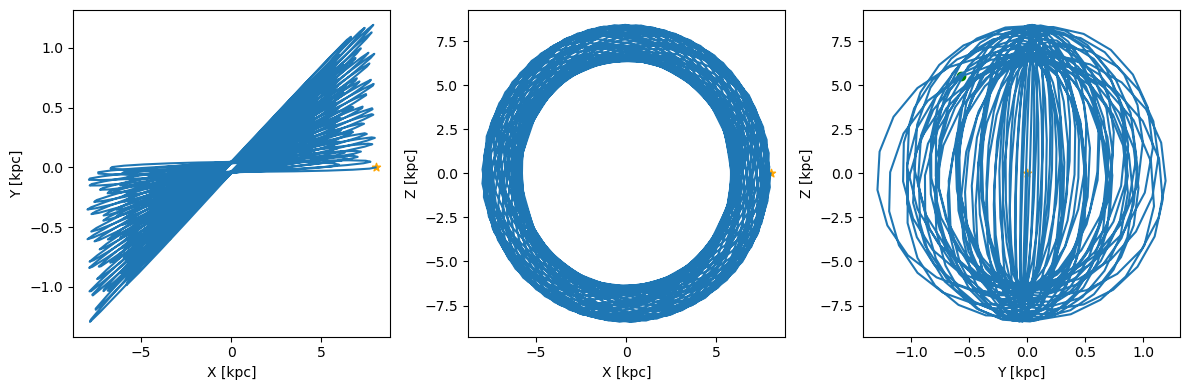

In [61]:
t=np.linspace(0,simulation_time,1000)
o=orb(t)
fig,ax=plt.subplots(1,3,figsize=(12,4))

ax[0].plot(o[:,0],o[:,1])
ax[0].scatter(final_pos[0],final_pos[1],c='orange',marker='*')
ax[0].scatter(mc_center[0],mc_center[1],c='green')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')


ax[1].plot(o[:,0],o[:,2])
ax[1].scatter(final_pos[0],final_pos[2],c='orange',marker='*')
ax[1].scatter(mc_center[0],mc_center[2],c='green')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].plot(o[:,1],o[:,2])
ax[2].scatter(final_pos[1],final_pos[2],c='orange',marker='*')
ax[2].scatter(mc_center[1],mc_center[2],c='green')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

In [62]:
def stellar_energy(N,M,R,v,its_sum):
    #b = np.sqrt(np.random.uniform(0, (1e-3)**2, N))
    b=np.random.uniform(100*R, (1e-4), N)
    E=((4*0.33*agama.G*agama.G*M*0.27*R*R)/((b**4)*(v**2)))
    E_sum=np.sum(E)
    E_rms_sum=np.sum(np.sqrt(E))**2
    if its_sum:
        return E_sum
    else:
        return E_rms_sum

In [63]:
def N_encounter_new(t,xv, b_max=1e-3): #stellar_rho_total use the better model
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)

In [64]:
tupd = 1e-2
time_i = 0


mc_mass=mc.mass
mc_rvir=mc.radius
print('simulation time',simulation_time)


simulation time 10


In [65]:
#random stuff for plotting
mc_array=[mc_center]
mc_time=[]
pnum_array=[]
mass_array,radius_array=[],[]
Ef_array,Ei_array,E2_array,E3_array,N_encounter_with_star_array =[],[],[],[],[]
color=[0]
SD=[]
SD_r=[]
SD_t=[]
SD_axis=[]
R_vector=[]
mean_axis_length=[]

In [ ]:
color_index=0
SD_count=0

while time_i < simulation_time-0.5*tupd:

    mc_time_center, mc_orbit_center = agama.orbit(ic=mc_center, potential=pot_mw, time=tupd,timestart=time_i,dtype=float, trajsize=1000, accuracy=1e-16,verbose=False)
    N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center)
    N_encounter_with_star_array.append(N_encounter_with_star)
    col_time=tupd/N_encounter_with_star
    its_sum=col_time<dynamical_time(mc_mass,mc_rvir)
    delE=stellar_energy(round(N_encounter_with_star),mc_mass,mc_rvir, np.mean(np.linalg.norm(mc_orbit_center[:,3:],axis=1)),its_sum)
    
    

    Eb=binding_energy(mc_mass,mc_rvir)
    Ei=total_energy(Eb)

    delEbyE=abs(delE/Eb)
    mass_loss=mc_mass*get_dm_frac(delEbyE)

    Ef=Ei+(1-get_fej(delEbyE))*delE-get_fub(delEbyE)*Ei
    
    Ef_array.append(Ef)
    Ei_array.append(Ei)
    E2_array.append((1-get_fej(delEbyE))*delE)
    E3_array.append(get_fub(delEbyE)*Ei)
    
    mc_mass_old=mc_mass
    mc_mass=mc_mass-mass_loss
    mc_rvir=((kappa/2-beta)*agama.G*mc_mass*mc_mass/Ef) if Ef<0 else 0

    mass_array.append(mc_mass)
    radius_array.append(mc_rvir)
    mc_array.append(mc_orbit_center)
    mc_time.append(mc_time_center[-1])

    #r_tidal=tidal_radius(np.linalg.norm(mc_center[:3]),mc_mass_old)
    r_tidal=tidal_radius(np.linalg.norm(mc_center[:3]),mc_mass)


    pnum=round(mass_loss*Nbody_total/mc.mass)
    pnum_array.append(pnum)
    if mc_rvir==0:
        print('dead')
        pnum=round(mc_mass_old*Nbody_total/mc.mass)
        mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass_old,r_tidal,pnum,pmass)
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        mcp_xv_temp+=mc_center
        mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
        mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=simulation_time-time_i, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=1)[:, 1])        
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        pca=PCA(n_components=3)
        mcp_xr=pca.fit_transform(mcp_xc)
        SD.append(pca.explained_variance_**0.5)
        alive=0
        break    
        
    if mcp_xv.size>0:
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=tupd, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=False)[:, 1])
    
    mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass,r_tidal,pnum,pmass)
    mcp_xv_temp+=mc_orbit_center[-1]  
    mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
    mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
    
    """if pnum>0 and color_index!=0:
        print('color_index:',color_index,'first')
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        color_index+=1
        print('time:',time_i,'pnum:',pnum,'mass:',mc_mass,'radius:',mc_rvir)
        fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0,sharex=0)
        ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],s=0.8,c=color,cmap='viridis')
        ax[0].scatter(mcp_xv_temp[:,0],mcp_xv_temp[:,1],s=2,c='orange') 
        ax[0].set_xlabel('X [kpc]')
        ax[0].set_ylabel('Y [kpc]')

        ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
        ax[1].scatter(mcp_xv_temp[:,0],mcp_xv_temp[:,2],s=2,c='orange')
        ax[1].set_xlabel('X [kpc]')
        ax[1].set_ylabel('Z [kpc]')

        ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
        ax[2].scatter(mcp_xv_temp[:,1],mcp_xv_temp[:,2],s=2,c='orange')
        ax[2].set_xlabel('Y [kpc]')
        ax[2].set_ylabel('Z [kpc]')
        ax[2].set
        plt.show()
        plt.tight_layout()    
    elif pnum>0 and color_index==0:
        print('color_index:',color_index,'second')
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)[1:]*color_index])
        color_index+=1
    plt.plot(mcp_xv[:,0], mcp_xv[:,1], 'o', markersize=1)
    plt.plot(mcp_xv_temp[:,0], mcp_xv_temp[:,1], 'o', markersize=2,color='orange')
    plt.plot(mc_orbit_center[-1][0], mc_orbit_center[-1][1], 's', markersize=5, color='red')
    plt.show()
    plt.plot(mcp_xv[:,0], mcp_xv[:,2], 'o', markersize=1)
    plt.plot(mcp_xv_temp[:,0], mcp_xv_temp[:,2], 'o', markersize=2,color='orange')
    plt.plot(mc_orbit_center[-1][0], mc_orbit_center[-1][2], 's', markersize=5, color='red')
    plt.show()
    plt.plot(mcp_xv[:,1], mcp_xv[:,2], 'o', markersize=1)
    plt.plot(mcp_xv_temp[:,1], mcp_xv_temp[:,2], 'o', markersize=2,color='orange')
    plt.plot(mc_orbit_center[-1][1], mc_orbit_center[-1][2], 's', markersize=5, color='red')
    plt.show()
    """

    if mcp_xv.size>1 and SD_count%1==0 and time_i>0:
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        pca=PCA(n_components=3)
        mcp_xr=pca.fit_transform(mcp_xc)
        SD.append(pca.explained_variance_**0.5)
        SD_t.append(time_i) 

        #pos=np.std(pos, axis=0)
        mean_axis_length.append(np.std(mcp_xv[:,:3],axis=0))

    mc_center = mc_orbit_center[-1]
    time_i += tupd
    


    SD_count+=1
    print(time_i,pnum)
#color=np.array(color[1:])
"""fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0,sharex=0)
ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],s=0.8,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],s=0.8,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')
plt.tight_layout()"""

In [ ]:
fig,ax=plt.subplots(4,2,figsize=(9,12),sharex=1)
ax[0,0].plot(mc_time,np.array(mass_array))
ax[0,0].set_ylabel('Mass')
ax[0,0].set_yscale('log')

ax[0,1].plot(mc_time,np.array(radius_array))
ax[0,1].set_ylabel('Radius')
ax[0,1].set_yscale('log')

ax[1,0].plot(mc_time,-np.array(Ef_array))
ax[1,0].set_ylabel('Ef')
ax[1,0].set_yscale('log')

ax[1,1].plot(mc_time,-np.array(Ei_array))
ax[1,1].set_ylabel('Ei')
ax[1,1].set_yscale('log')

ax[2,0].plot(mc_time,np.array(E2_array))
ax[2,0].set_ylabel('E2=(1-fej)*delE')
ax[2,0].set_yscale('log')

ax[2,1].plot(mc_time,-np.array(E3_array))
ax[2,1].set_ylabel('E3=fub*Ei')
ax[2,1].set_yscale('log')

ax[3,0].plot(mc_time,N_encounter_with_star_array)
ax[3,0].set_ylabel('N_enc')
ax[3,0].set_yscale('log')

ax[3,1].plot(mc_time,pnum_array)
ax[3,1].set_ylabel('Pnum')
ax[3,1].set_yscale('log')

fig.supxlabel('Time(Gyr)')

plt.tight_layout()

In [ ]:
fig,ax=plt.subplots(1,3,figsize=(12,4))

ax[0].plot(o[:,0],o[:,1],lw=0.2)
ax[0].scatter(mc_end[0],mc_end[1],c='orange',marker='*',s=200)
ax[0].scatter(mc_start[0],mc_start[1],c='green')
ax[0].scatter(mcp_xv[:,0],mcp_xv[:,1],c='r')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')


ax[1].plot(o[:,0],o[:,2],lw=0.2)
ax[1].scatter(mc_end[0],mc_end[2],c='orange',marker='*',s=200)
ax[1].scatter(mc_start[0],mc_start[2],c='green')
ax[1].scatter(mcp_xv[:,0],mcp_xv[:,2],c='r')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].plot(o[:,1],o[:,2],lw=0.2)
ax[2].scatter(mc_end[1],mc_end[2],c='orange',marker='*',s=200)
ax[2].scatter(mc_start[1],mc_start[2],c='green')
ax[2].scatter(mcp_xv[:,1],mcp_xv[:,2],c='r')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()
plt.show()


In [ ]:
fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=1,sharex=1)
sc=ax[0].scatter(mcp_xc[:,0],mcp_xc[:,1],s=1,c=color,cmap='viridis')

ax[0].scatter(mcp_xc[:,0],mcp_xc[:,1],s=1,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xc[:,0],mcp_xc[:,2],s=1,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xc[:,1],mcp_xc[:,2],s=1,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

x0, x1 = ax[0].get_xlim()
y0, y1 = ax[0].get_ylim()
w = max(x1 - x0, y1 - y0)
xc, yc = (x0 + x1) / 2, (y0 + y1) / 2
ax[0].set_xlim(xc - w/2, xc + w/2)
ax[0].set_ylim(yc - w/2, yc + w/2)
x0, x1 = ax[1].get_xlim()
y0, y1 = ax[1].get_ylim()
w = max(x1 - x0, y1 - y0)
xc, yc = (x0 + x1) / 2, (y0 + y1) / 2
ax[1].set_xlim(xc - w/2, xc + w/2)
ax[1].set_ylim(yc - w/2, yc + w/2)
x0, x1 = ax[2].get_xlim()
y0, y1 = ax[2].get_ylim()
w = max(x1 - x0, y1 - y0)
xc, yc = (x0 + x1) / 2, (y0 + y1) / 2
ax[2].set_xlim(xc - w/2, xc + w/2)
ax[2].set_ylim(yc - w/2, yc + w/2)

fig.colorbar(sc,ax=ax)

#plt.tight_layout()

In [ ]:
plt.plot(SD)
plt.yscale('log') #vy=1
plt.ylim((1e-9,1e-5))
plt.axhline(y=4e-7)

In [ ]:
SD

In [ ]:
plt.plot(SD)
plt.yscale('log') #for vy=10

In [ ]:
SD_arr = np.array(SD)
plt.plot(SD_t, SD_arr[:,0], label=r'$\sigma_x$')
plt.plot(SD_t, SD_arr[:,1], label=r'$\sigma_y$')
plt.plot(SD_t, SD_arr[:,2], label=r'$\sigma_z$')
plt.xlabel('time')
plt.ylabel(r'$\sigma$ [kpc]')
plt.legend()
plt.yscale('log')

In [ ]:
plt.plot(np.array(mean_axis_length),lw=1)
plt.yscale('log')

In [ ]:
plt.plot(mean_axis_length)
plt.yscale('log')

In [ ]:
#check why disoriented streams.

In [ ]:
fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=0,sharex=0)
sc=ax[0].scatter(mcp_xc[:,0],mcp_xc[:,1],s=0.1)
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xc[:,0],mcp_xc[:,2],s=0.1)
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xc[:,1],mcp_xc[:,2],s=0.1)
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')
fig.colorbar(sc,ax=ax)


#plt.tight_layout()

In [ ]:
pca=PCA(n_components=3)
mcp_xr=pca.fit_transform(mcp_xc)
print('SD along axes:',pca.explained_variance_**0.5)
print('principal axes (rows):\n',pca.components_)

for k in np.unique(color)[:-1]:
    m = color==k
    print(k,len(mcp_xc[m,0]))
    plt.scatter(mcp_xc[m,0], mcp_xc[m,2], s=3, label=int(k))
plt.show()


In [ ]:
pca=PCA(n_components=3)
xc=pca.fit_transform(mcp_xv)

In [ ]:
fig,ax=plt.subplots(1,3,figsize=(8,4),sharey=0,sharex=0)
ax[0].scatter(xc[:,0],xc[:,1],s=0.1,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(xc[:,0],xc[:,2],s=0.1,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(xc[:,1],xc[:,2],s=0.1,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')


plt.tight_layout()

In [ ]:
pca.explained_variance_

In [ ]:
sigma=np.sqrt(agama.G*mc.mass/mc.radius)
sigma

In [ ]:
V=np.sqrt(agama.G*pot_mw.enclosedMass(8)/8)
V

In [ ]:
V*np.sqrt(mc.mass*8/mc.radius/pot_mw.enclosedMass(8))


In [ ]:
F_der=pot_mw.eval(o[:,:3],der=1)


In [ ]:
for i in F_der:
    print(i)

In [ ]:

T = np.array([[F_der[:,0], F_der[:,3], F_der[:,5]],
              [F_der[:,3], F_der[:,1], F_der[:,4]],
              [F_der[:,5], F_der[:,4], F_der[:,2]]]).transpose(2,0,1)   # (N,3,3)

eigvals, eigvecs = np.linalg.eigh(T)   

lam_max  = eigvals[:,-1]          # (N,)
axis_max = eigvecs[:,:,-1]        # (N,3) unit vectors, the stretching direction


In [ ]:
axis_max

In [ ]:
np.abs(axis_max) 
np.degrees(np.arccos(cos_xyz))  

In [ ]:
dominant = np.argmax(np.abs(axis_max), axis=1)    # (N,)  0 = x, 1 = y, 2 = z
labels = np.array(['x', 'y', 'z'])[dominant]
cos_xyz = np.abs(axis_max)                          # (N,3), each between 0 and 1
ang_xyz = np.degrees(np.arccos(cos_xyz))            # angle to x, y, z axes in degrees
import matplotlib.pyplot as plt

ang_xyz = np.degrees(np.arccos(np.clip(np.abs(axis_max), 0, 1)))   # (N,3)

plt.plot(ang_xyz[:,0], label='x',c='r')
plt.show()
plt.plot(ang_xyz[:,1], label='y',c='g')
plt.show()
plt.plot(ang_xyz[:,2], label='z',c='b')
plt.show()
plt.xlabel('orbit step')
plt.ylabel('angle to axis [deg]')
plt.legend()
plt.show()


In [ ]:
plt.plot(eigvals[:,0],color='r')
plt.plot(eigvals[:,1],color='g')
plt.plot(eigvals[:,2],color='b')

In [ ]:
for t in F_der:
    xx, yy, zz, xy, yz, zx = t
    T = np.array([[xx, xy, zx],
                [xy, yy, yz],
                [zx, yz, zz]])
    w, v = np.linalg.eigh(T)
    lam = w[-1]          # largest eigenvalue = stretching
    e = v[:, -1]         # stretching axis

    # angles to x, y, z axes
    angles = np.degrees(np.arccos(np.abs(e)))
    dominant = "xyz"[np.argmax(np.abs(e))]

    print("dominant axis   :", dominant)  
    print(w)

In [ ]:
plt.plot(np.array(mean_axis_length)[:,1],lw=1)
plt.yscale('log')

In [ ]:
for i in range(6):
    fig,ax=plt.subplots(1,2,figsize=(12,4))
    ax[0].plot(F_der[:,i])
    ax[1].plot(o[:,i])
    plt.show()

In [ ]:
s_array=F_der[:,0]*1e-4*r_tidal
s_array.sum()

In [ ]:
s_array=F_der[:,1]*1e-4*r_tidal
s_array.sum()

In [ ]:
s_array=F_der[:,2]*1e-4*r_tidal
s_array.sum()

In [ ]:
pot_mw.potential(mc_center[:3])

In [ ]:
pot_point = agama.Potential(type='Plummer', mass=pot_mw.enclosedMass(8), scaleRadius=1e-2, center=[0, 0, 0])


In [ ]:
orb2=agama.orbit(ic=mc_center, potential=pot_point, time=simulation_time, timestart=0, dtype=object, accuracy=1e-10, verbose=False)

In [ ]:
t=np.linspace(0,simulation_time,1000)
o=orb2(t)
fig,ax=plt.subplots(1,3,figsize=(12,4))

ax[0].plot(o[:,0],o[:,1])
ax[0].scatter(final_pos[0],final_pos[1],c='orange',marker='*')
ax[0].scatter(mc_center[0],mc_center[1],c='green')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')


ax[1].plot(o[:,0],o[:,2])
ax[1].scatter(final_pos[0],final_pos[2],c='orange',marker='*')
ax[1].scatter(mc_center[0],mc_center[2],c='green')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].plot(o[:,1],o[:,2])
ax[2].scatter(final_pos[1],final_pos[2],c='orange',marker='*')
ax[2].scatter(mc_center[1],mc_center[2],c='green')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

In [ ]:
F_der=pot_point.eval(o[:,:3],der=1)
for t in F_der:
    xx, yy, zz, xy, yz, zx = t
    T = np.array([[xx, xy, zx],
                [xy, yy, yz],
                [zx, yz, zz]])
    print(T[0][0],T[1][1],T[2][2])

In [ ]:
fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=1,sharex=1)
ax[0].plot(F_der[:,0],c='r',lw=1)
ax[1].plot(F_der[:,1],c='g',lw=1)
ax[2].plot(F_der[:,2],c='b',lw=1)
ax[0].axhline(y=0)
ax[1].axhline(y=0)
ax[2].axhline(y=0)

In [ ]:
#crossover when \sigma*t takes over 0.5at2
a=-F_der[:,1].mean()*r_tidal*r_tidal
2*sigma/a

In [ ]:
fig,ax=plt.subplots(1,3,figsize=(12,4),sharey=1,sharex=1)
ax[0].plot(F_der[:,0],c='r',lw=1)
ax[1].plot(F_der[:,1],c='g',lw=1)
ax[2].plot(F_der[:,2],c='b',lw=1)
ax[0].axhline(y=0)
ax[1].axhline(y=0)
ax[2].axhline(y=0)

In [ ]:
mcp_xv_extended = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=5, timestart=0, trajsize=1, accuracy=1e-16,dtype=float,verbose=1)[:, 1])        


In [ ]:
fig,ax=plt.subplots(1,3,figsize=(8,4),sharey=0,sharex=0)
ax[0].scatter(mcp_xv_extended[:,0],mcp_xv_extended[:,1],s=0.1,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(mcp_xv_extended[:,0],mcp_xv_extended[:,2],s=0.1,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(mcp_xv_extended[:,1],mcp_xv_extended[:,2],s=0.1,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')

plt.tight_layout()

In [ ]:
pca=PCA(n_components=3)
xc_extended=pca.fit_transform(mcp_xv_extended)

In [ ]:
fig,ax=plt.subplots(1,3,figsize=(8,4),sharey=0,sharex=0)
ax[0].scatter(xc_extended[:,0],xc_extended[:,1],s=0.1,c=color,cmap='viridis')
ax[0].set_xlabel('X [kpc]')
ax[0].set_ylabel('Y [kpc]')

ax[1].scatter(xc_extended[:,0],xc_extended[:,2],s=0.1,c=color,cmap='viridis')
ax[1].set_xlabel('X [kpc]')
ax[1].set_ylabel('Z [kpc]')

ax[2].scatter(xc_extended[:,1],xc_extended[:,2],s=0.1,c=color,cmap='viridis')
ax[2].set_xlabel('Y [kpc]')
ax[2].set_ylabel('Z [kpc]')


plt.tight_layout()

In [ ]:
np.set_printoptions(suppress=True, precision=2)
pca.explained_variance_ratio_*100

In [ ]:
#so the shear in the x-y axis is what causes the elongation in y, which both have the same nature 

In [ ]:

import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1)  # kpc, km/s, Solar mass
from scipy.stats import uniform_direction

def generate_mc_particles(M,R, N,pmass):
    
    m_array=np.ones(N)*pmass
    pos_unit=uniform_direction(3).rvs(N)  # shape (N, 3)
    coords=R*pos_unit
    vel_unit = uniform_direction(3).rvs(N)  # shape (N, 3)
    v_ideal=np.sqrt(agama.G*M/R)
    vel=v_ideal*vel_unit
    return np.column_stack([coords, vel]), m_array



In [ ]:
mc = Minicluster(mass=get_mass(), delta=50, concentration=10)
Nbody_total=1e4
pmass=mc.mass/Nbody_total
print('mass and radius:',mc.mass,mc.radius,pmass)


In [ ]:
xv=generate_mc_particles(mc.mass,mc.radius,10,pmass)[0]
x=xv[:,:3]
v=xv[:,3:]
fig,ax=plt.subplots(1,3,figsize=(15,5))
ax[0].scatter(x[:,0],x[:,1])
ax[1].scatter(x[:,0],x[:,2])
ax[2].scatter(x[:,1],x[:,2])

In [ ]:
speed=np.linalg.norm(v,axis=1)
print(speed)
plt.hist(speed)

In [ ]:
delE

In [ ]:
0.5*agama.G*mc.mass/mc.radius

In [66]:
a,b=[],[]

In [67]:
color_index=0
SD_count=0

while time_i < simulation_time-0.5*tupd:

    mc_time_center, mc_orbit_center = agama.orbit(ic=mc_center, potential=pot_mw, time=tupd,timestart=time_i,dtype=float, trajsize=1000, accuracy=1e-16,verbose=False)
    N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center)
    N_encounter_with_star_array.append(N_encounter_with_star)
    col_time=tupd/N_encounter_with_star
    its_sum=col_time<dynamical_time(mc_mass,mc_rvir)
    delE=stellar_energy(round(N_encounter_with_star),mc_mass,mc_rvir, np.mean(np.linalg.norm(mc_orbit_center[:,3:],axis=1)),its_sum)
    print(delE,0.5*agama.G*mc_mass/mc_rvir)
    
    a.append(delE)
    b.append(0.5*agama.G*mc_mass/mc_rvir)

    if (delE>0.5*agama.G*mc_mass/mc_rvir):
        print(delE,0.5*agama.G*mc_mass/mc_rvir)
    
    Eb=binding_energy(mc_mass,mc_rvir)
    Ei=total_energy(Eb)

    delEbyE=abs(delE/Eb)
    mass_loss=mc_mass*get_dm_frac(delEbyE)

    Ef=Ei+(1-get_fej(delEbyE))*delE-get_fub(delEbyE)*Ei
    
    Ef_array.append(Ef)
    Ei_array.append(Ei)
    E2_array.append((1-get_fej(delEbyE))*delE)
    E3_array.append(get_fub(delEbyE)*Ei)
    
    mc_mass_old=mc_mass
    mc_mass=mc_mass-mass_loss
    mc_rvir=((kappa/2-beta)*agama.G*mc_mass*mc_mass/Ef) if Ef<0 else 0

    mass_array.append(mc_mass)
    radius_array.append(mc_rvir)
    mc_array.append(mc_orbit_center)
    mc_time.append(mc_time_center[-1])

    r_tidal=tidal_radius(np.linalg.norm(mc_center[:3]),mc_mass)


    pnum=round(mass_loss*Nbody_total/mc.mass)
    pnum_array.append(pnum)
    if mc_rvir==0:
        print('dead')
        pnum=round(mc_mass_old*Nbody_total/mc.mass)
        mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass_old,r_tidal,pnum,pmass)
        color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
        mcp_xv_temp+=mc_center
        mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
        mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=simulation_time-time_i, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=1)[:, 1])        
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        pca=PCA(n_components=3)
        mcp_xr=pca.fit_transform(mcp_xc)
        SD.append(pca.explained_variance_**0.5)
        alive=0
        break    
        
    if mcp_xv.size>0:
        mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=tupd, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=False)[:, 1])
    
    mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass,r_tidal,pnum,pmass)
    mcp_xv_temp+=mc_orbit_center[-1]  
    mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
    mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
    
    if mcp_xv.size>1 and SD_count%1==0 and time_i>0:
        mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
        pca=PCA(n_components=3)
        mcp_xr=pca.fit_transform(mcp_xc)
        SD.append(pca.explained_variance_**0.5)
        SD_t.append(time_i) 

        #pos=np.std(pos, axis=0)
        mean_axis_length.append(np.std(mcp_xv[:,:3],axis=0))

    mc_center = mc_orbit_center[-1]
    time_i += tupd
    


    SD_count+=1
    #print(time_i,pnum)
#color=np.array(color[1:])


1.0249647996941949e-35 4.554020923417941e-08
3.3696838550079354e-32 4.5540209234179364e-08
1.0800437345637018e-25 4.554020923403835e-08
1.396543605914849e-31 4.553975671672515e-08
1.717642264217042e-35 4.553975671614073e-08
0.0 4.553975671614066e-08
0.0 4.553975671614066e-08
0.0 4.553975671614066e-08
0.0 4.553975671614066e-08
0.0 4.553975671614066e-08
0.0 4.553975671614066e-08
5.0893483750281856e-36 4.553975671614066e-08
4.3242669048723986e-32 4.5539756716140646e-08
2.2960645295831302e-26 4.5539756715959685e-08
5.3929065374028045e-28 4.553966052068232e-08
1.5981638719328198e-34 4.553965826385292e-08
1.5380904341592087e-35 4.553965826385225e-08
0.0 4.553965826385219e-08
0.0 4.553965826385219e-08
0.0 4.553965826385219e-08
0.0 4.553965826385219e-08
3.842319095228009e-36 4.553965826385219e-08
5.491183870751107e-34 4.553965826385217e-08
1.502966407351171e-27 4.5539658263849876e-08
5.737694739522342e-29 4.5539651974219676e-08
3.590902540649699e-35 4.5539651734108004e-08
0.0 4.553965173410786

ValueError: n_components=3 must be between 0 and min(n_samples, n_features)=2 with svd_solver='full'

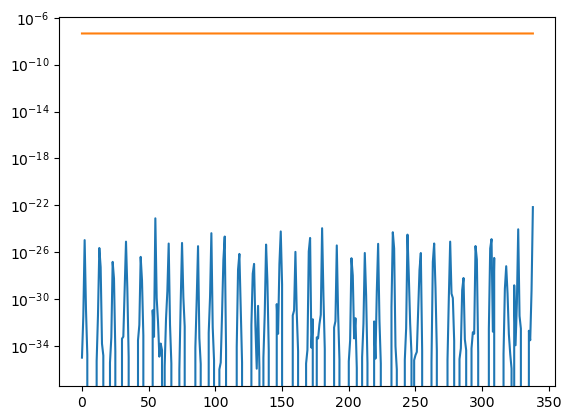

In [70]:
plt.plot(a)
plt.plot(b)
plt.yscale('log')

In [71]:
mcp_xv

array([[  -6.00155951,   -0.67645363,   -2.17091111,   37.62344635,
           2.90766337, -250.87960988],
       [  -6.00155957,   -0.6764536 ,   -2.17091115,   37.62344635,
           2.90766337, -250.87960988]])